# Predicting COVID-19 Mortality from Patient Health Data

**Goal:** given a confirmed COVID-19 patient's demographics and health conditions, estimate the probability that they die from the disease.

This notebook started as a final group project for an Intro to Machine Learning class. It walks through:

1. Cleaning and encoding the data
2. Choosing features with L1 (lasso) regularization
3. Comparing logistic regression, a decision tree and k-nearest neighbors with cross-validated grid search
4. Handling class imbalance (only ~14% of confirmed patients died)
5. Evaluating the final model on a held-out test set

We train two versions of the model:

- **Full model:** uses every feature, including hospital-course information (hospitalized, intubated, ICU, pneumonia).
- **Pre-existing conditions model:** uses only what is known about a patient *before* they get sick (age, sex, pregnancy and chronic conditions). This is the version that answers "how risky is COVID for someone with these health issues?"

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
DATA_PATH = Path("data") / "Covid Data.csv"
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.dpi"] = 110

## Load the data

The dataset comes from the Mexican government's COVID-19 patient records, published on Kaggle as the [COVID-19 Dataset](https://www.kaggle.com/datasets/meirnizri/covid19-dataset). Download it and place `Covid Data.csv` in a `data/` folder next to this notebook.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Download the dataset from "
        "https://www.kaggle.com/datasets/meirnizri/covid19-dataset "
        "and put 'Covid Data.csv' in the data/ folder."
    )

raw = pd.read_csv(DATA_PATH)
print(f"{len(raw):,} patients, {raw.shape[1]} columns")
raw.head()

1,048,575 patients, 21 columns


,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,...,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,03/05/2020,97,1,65,2,2,...,2,2,1,2,2,2,2,2,3,97
1,2,1,2,1,03/06/2020,97,1,72,97,2,...,2,2,1,2,2,1,1,2,5,97
2,2,1,2,2,09/06/2020,1,2,55,97,1,...,2,2,2,2,2,2,2,2,3,2
3,2,1,1,1,12/06/2020,97,2,53,2,2,...,2,2,2,2,2,2,2,2,7,97
4,2,1,2,1,21/06/2020,97,2,68,97,1,...,2,2,1,2,2,2,2,2,3,97


## Clean and encode

How the raw data is coded:

- Yes/no columns use **1 = yes** and **2 = no**.
- **97** means "not applicable." For example, `PREGNANT` is 97 for every male patient, and `INTUBED`/`ICU` are 97 for patients who were sent home.
- **98 and 99** mean the value is unknown.
- `CLASIFFICATION_FINAL` values 1–3 are confirmed COVID cases. 4 and above are negative or inconclusive.
- `DATE_DIED` is `9999-99-99` for patients who survived.

The steps below:

1. Keep only confirmed cases.
2. Create the target `DIED` (1 = died, 0 = survived).
3. Recode yes/no columns to **1 = yes, 0 = no**.
4. Treat "not applicable" (97) as 0. A man isn't pregnant, and a patient who was sent home wasn't intubated.
5. Drop the ~1.5% of rows that still have an unknown (98/99) value.
6. Drop `USMER` and `MEDICAL_UNIT`, which describe the hospital rather than the patient.

In [3]:
df = raw[raw["CLASIFFICATION_FINAL"] < 4].copy()
df["DIED"] = (df["DATE_DIED"] != "9999-99-99").astype(int)
df = df.drop(columns=["USMER", "MEDICAL_UNIT", "DATE_DIED", "CLASIFFICATION_FINAL"])

# SEX: 1 = female, 2 = male.  PATIENT_TYPE: 1 = sent home, 2 = hospitalized.
df["MALE"] = (df.pop("SEX") == 2).astype(int)
df["HOSPITALIZED"] = (df.pop("PATIENT_TYPE") == 2).astype(int)

yes_no_cols = ["INTUBED", "PNEUMONIA", "PREGNANT", "DIABETES", "COPD", "ASTHMA",
               "INMSUPR", "HIPERTENSION", "OTHER_DISEASE", "CARDIOVASCULAR",
               "OBESITY", "RENAL_CHRONIC", "TOBACCO", "ICU"]

unknown = df[yes_no_cols].isin([98, 99]).any(axis=1)
print(f"Dropping {unknown.sum():,} rows ({unknown.mean():.1%}) with unknown values")
df = df[~unknown]

df[yes_no_cols] = df[yes_no_cols].replace({1: 1, 2: 0, 97: 0}).astype(int)

# Clearer column names (the originals keep the dataset's Spanish-influenced spelling)
df = df.rename(columns={"INMSUPR": "IMMUNOSUPPRESSED", "HIPERTENSION": "HYPERTENSION",
                        "RENAL_CHRONIC": "CHRONIC_KIDNEY_DISEASE"})

print(f"{len(df):,} confirmed cases remain; mortality rate = {df['DIED'].mean():.1%}")
df.head()

Dropping 5,879 rows (1.5%) with unknown values


386,100 confirmed cases remain; mortality rate = 13.5%


,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,COPD,ASTHMA,IMMUNOSUPPRESSED,HYPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,CHRONIC_KIDNEY_DISEASE,TOBACCO,ICU,DIED,MALE,HOSPITALIZED
0,0,1,65,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
2,1,0,55,0,1,0,0,0,0,0,0,0,0,0,0,1,1,1
4,0,0,68,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0
5,0,1,40,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
6,0,0,64,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## A quick look at the data

Mortality rises steeply with age, and it is much higher among patients with certain conditions.

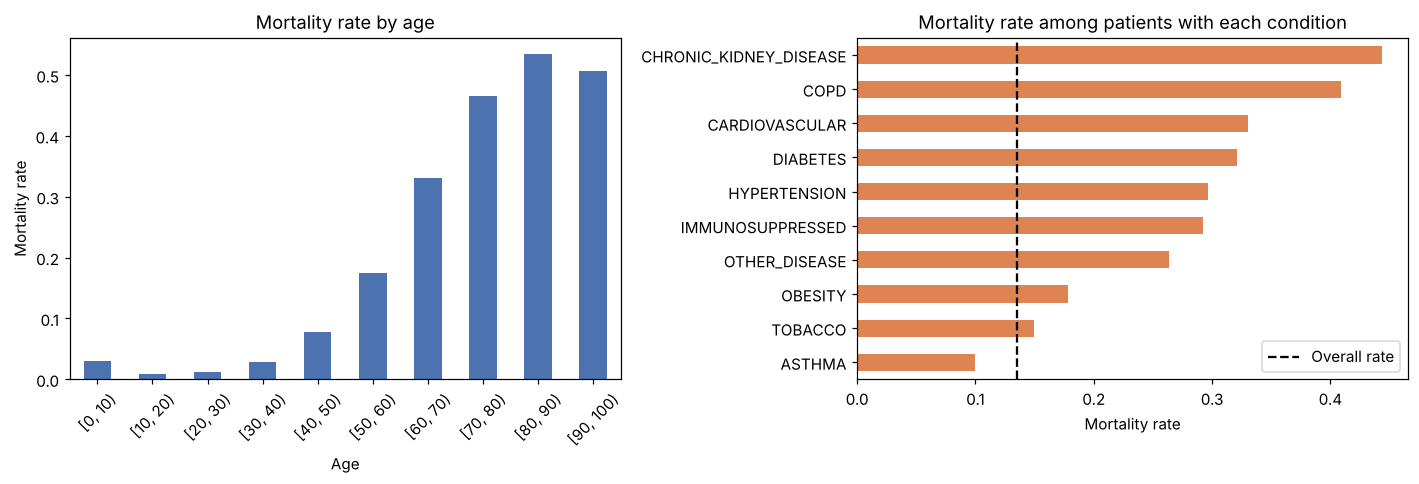

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

age_bins = pd.cut(df["AGE"], bins=range(0, 101, 10), right=False)
df.groupby(age_bins, observed=True)["DIED"].mean().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="Mortality rate by age", xlabel="Age", ylabel="Mortality rate")
axes[0].tick_params(axis="x", rotation=45)

conditions = ["DIABETES", "COPD", "ASTHMA", "IMMUNOSUPPRESSED", "HYPERTENSION",
              "OTHER_DISEASE", "CARDIOVASCULAR", "OBESITY", "CHRONIC_KIDNEY_DISEASE", "TOBACCO"]
rates = pd.Series({c: df.loc[df[c] == 1, "DIED"].mean() for c in conditions}).sort_values()
rates.plot.barh(ax=axes[1], color="#DD8452")
axes[1].axvline(df["DIED"].mean(), color="black", ls="--", label="Overall rate")
axes[1].set(title="Mortality rate among patients with each condition", xlabel="Mortality rate")
axes[1].legend()

plt.tight_layout()
plt.savefig(IMAGE_DIR / "eda_mortality.png", bbox_inches="tight")
plt.show()

## Train/test split

We hold out 20% of patients as a test set and don't touch it until the very end. The split is **stratified**, so both sets keep the same ~14% mortality rate. Model selection uses 5-fold cross-validation on the training set only.

In [5]:
FULL_FEATURES = ["AGE", "MALE", "PREGNANT", "DIABETES", "COPD", "ASTHMA", "IMMUNOSUPPRESSED",
                 "HYPERTENSION", "OTHER_DISEASE", "CARDIOVASCULAR", "OBESITY",
                 "CHRONIC_KIDNEY_DISEASE", "TOBACCO",
                 "HOSPITALIZED", "PNEUMONIA", "INTUBED", "ICU"]
PRE_EXISTING_FEATURES = FULL_FEATURES[:13]  # everything before the hospital-course columns

X = df[FULL_FEATURES]
y = df["DIED"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,}  Test: {len(X_test):,}")
print(f"Mortality rate - train: {y_train.mean():.2%}, test: {y_test.mean():.2%}")

Train: 308,880  Test: 77,220
Mortality rate - train: 13.50%, test: 13.50%


## Feature selection with L1 regularization

An L1 (lasso) penalty pushes the coefficients of uninformative features to exactly zero. We fit it on the **training set only** and keep the features with non-zero coefficients. Features are standardized first so the coefficients can be compared.

Full model keeps: ['AGE', 'MALE', 'DIABETES', 'COPD', 'IMMUNOSUPPRESSED', 'HYPERTENSION', 'OTHER_DISEASE', 'OBESITY', 'CHRONIC_KIDNEY_DISEASE', 'HOSPITALIZED', 'PNEUMONIA', 'INTUBED', 'ICU']
Dropped: ['ASTHMA', 'CARDIOVASCULAR', 'PREGNANT', 'TOBACCO']

Pre-existing model keeps: ['AGE', 'MALE', 'DIABETES', 'COPD', 'IMMUNOSUPPRESSED', 'HYPERTENSION', 'OTHER_DISEASE', 'OBESITY', 'CHRONIC_KIDNEY_DISEASE', 'TOBACCO']
Dropped: ['ASTHMA', 'CARDIOVASCULAR', 'PREGNANT']


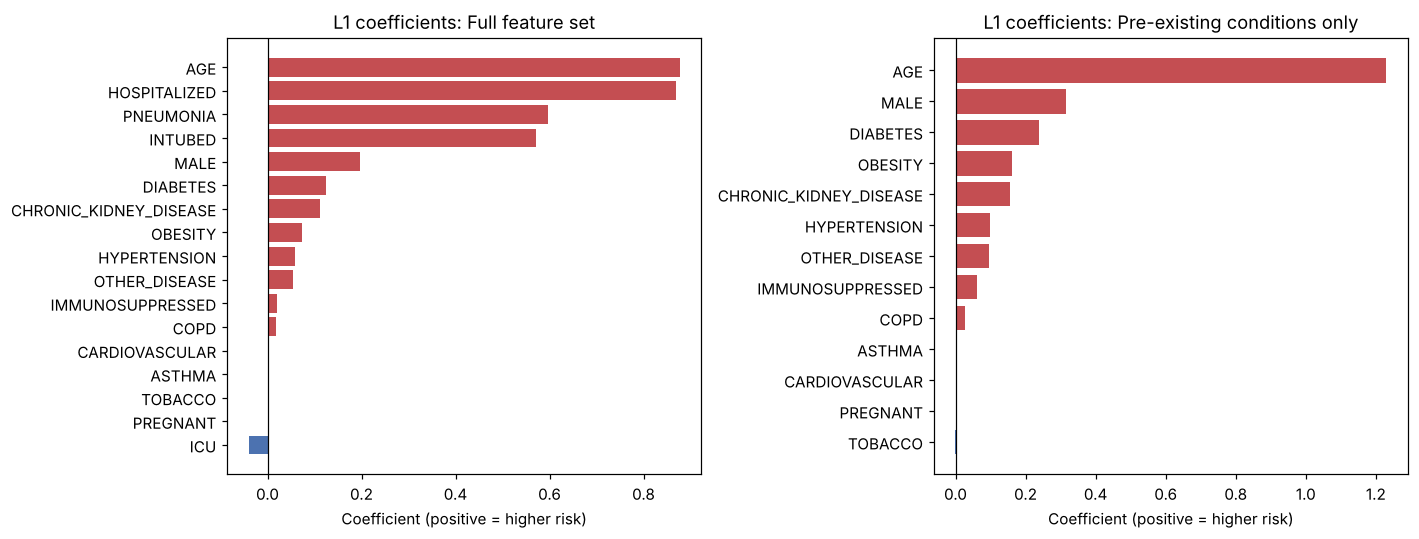

In [6]:
def l1_selected_features(features, C=0.001):
    lasso = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(l1_ratio=1, solver="liblinear", C=C,
                                     class_weight="balanced", random_state=RANDOM_STATE)),
    ])
    lasso.fit(X_train[features], y_train)
    coefs = pd.Series(lasso.named_steps["model"].coef_[0], index=features)
    return coefs, list(coefs[coefs != 0].index)

full_coefs, full_selected = l1_selected_features(FULL_FEATURES)
pre_coefs, pre_selected = l1_selected_features(PRE_EXISTING_FEATURES)

print("Full model keeps:", full_selected)
print("Dropped:", sorted(set(FULL_FEATURES) - set(full_selected)))
print()
print("Pre-existing model keeps:", pre_selected)
print("Dropped:", sorted(set(PRE_EXISTING_FEATURES) - set(pre_selected)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, coefs, title in [(axes[0], full_coefs, "Full feature set"),
                         (axes[1], pre_coefs, "Pre-existing conditions only")]:
    coefs = coefs.sort_values()
    ax.barh(coefs.index, coefs.values,
            color=["#C44E52" if v > 0 else "#4C72B0" for v in coefs.values])
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"L1 coefficients: {title}", xlabel="Coefficient (positive = higher risk)")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "l1_coefficients.png", bbox_inches="tight")
plt.show()

## Model comparison

We compare three classifiers with a grid search over their main hyperparameters.

**Handling imbalance.** Only ~14% of patients died. A model that always predicts "survived" would be 86% accurate and completely useless. To fix this, each candidate is wrapped in a pipeline that **randomly oversamples the death class inside each training fold**. Because the oversampling happens inside the pipeline, duplicated rows never leak into the folds or the test set used for scoring.

**Scoring.** We pick the best model by **ROC AUC**, which measures how well the model ranks high-risk patients above low-risk ones regardless of the decision threshold. Accuracy is misleading with imbalanced classes.

KNN is slow on ~300k rows, so its grid search runs on a 50k-row stratified sample of the training set.

In [7]:
def make_pipeline(model, scale=False):
    steps = [("oversample", RandomOverSampler(random_state=RANDOM_STATE))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

candidates = {
    "Logistic regression": (
        make_pipeline(LogisticRegression(max_iter=5000), scale=True),
        {"model__C": [0.01, 1, 100]}),
    "Decision tree": (
        make_pipeline(DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)),
        {"model__max_depth": [3, 5, 7, 9, 11]}),
    "K-nearest neighbors": (
        make_pipeline(KNeighborsClassifier(), scale=True),
        {"model__n_neighbors": [5, 15, 51]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_knn_sample, _, y_knn_sample, _ = train_test_split(
    X_train, y_train, train_size=50_000, stratify=y_train, random_state=RANDOM_STATE)

def compare_models(features):
    rows, fitted = [], {}
    for name, (pipe, grid) in candidates.items():
        Xs, ys = (X_knn_sample, y_knn_sample) if name == "K-nearest neighbors" else (X_train, y_train)
        search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
        search.fit(Xs[features], ys)
        fitted[name] = search
        best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
        rows.append({"Model": name, "Best params": best, "CV ROC AUC": search.best_score_})
    return pd.DataFrame(rows).sort_values("CV ROC AUC", ascending=False), fitted

full_results, full_searches = compare_models(full_selected)
full_results.style.format({"CV ROC AUC": "{:.4f}"}).hide(axis="index")

Model,Best params,CV ROC AUC
Decision tree,{'max_depth': 7},0.9473
Logistic regression,{'C': 100},0.9465
K-nearest neighbors,{'n_neighbors': 51},0.9382


In [8]:
pre_results, pre_searches = compare_models(pre_selected)
pre_results.style.format({"CV ROC AUC": "{:.4f}"}).hide(axis="index")

Model,Best params,CV ROC AUC
Logistic regression,{'C': 0.01},0.8441
Decision tree,{'max_depth': 7},0.8416
K-nearest neighbors,{'n_neighbors': 51},0.8226


## Final evaluation on the held-out test set

For each feature set, we take the model with the best cross-validated AUC. Its pipeline has already been refit on the full training set, and we now score it on the test set for the first time.

For a mortality model, **recall on the death class** is the key number: what fraction of patients who actually died did the model flag as high-risk?

In [9]:
def evaluate(results, searches, features, label):
    best_name = results.iloc[0]["Model"]
    model = searches[best_name].best_estimator_
    if best_name == "K-nearest neighbors":
        # KNN was tuned on a sample; refit it on the full training set
        model.fit(X_train[features], y_train)
    proba = model.predict_proba(X_test[features])[:, 1]
    pred = (proba >= 0.5).astype(int)

    print(f"=== {label}: {best_name} ===")
    print(f"Test ROC AUC: {roc_auc_score(y_test, proba):.4f}\n")
    print(classification_report(y_test, pred, target_names=["Survived", "Died"], digits=3))
    return best_name, model, proba, pred

full_name, full_model, full_proba, full_pred = evaluate(
    full_results, full_searches, full_selected, "Full model")
pre_name, pre_model, pre_proba, pre_pred = evaluate(
    pre_results, pre_searches, pre_selected, "Pre-existing conditions model")

=== Full model: Decision tree ===
Test ROC AUC: 0.9472

              precision    recall  f1-score   support

    Survived      0.988     0.838     0.907     66792
        Died      0.473     0.932     0.628     10428

    accuracy                          0.851     77220
   macro avg      0.730     0.885     0.767     77220
weighted avg      0.918     0.851     0.869     77220

=== Pre-existing conditions model: Logistic regression ===
Test ROC AUC: 0.8437

              precision    recall  f1-score   support

    Survived      0.957     0.767     0.851     66792
        Died      0.342     0.778     0.475     10428

    accuracy                          0.768     77220
   macro avg      0.650     0.772     0.663     77220
weighted avg      0.874     0.768     0.801     77220



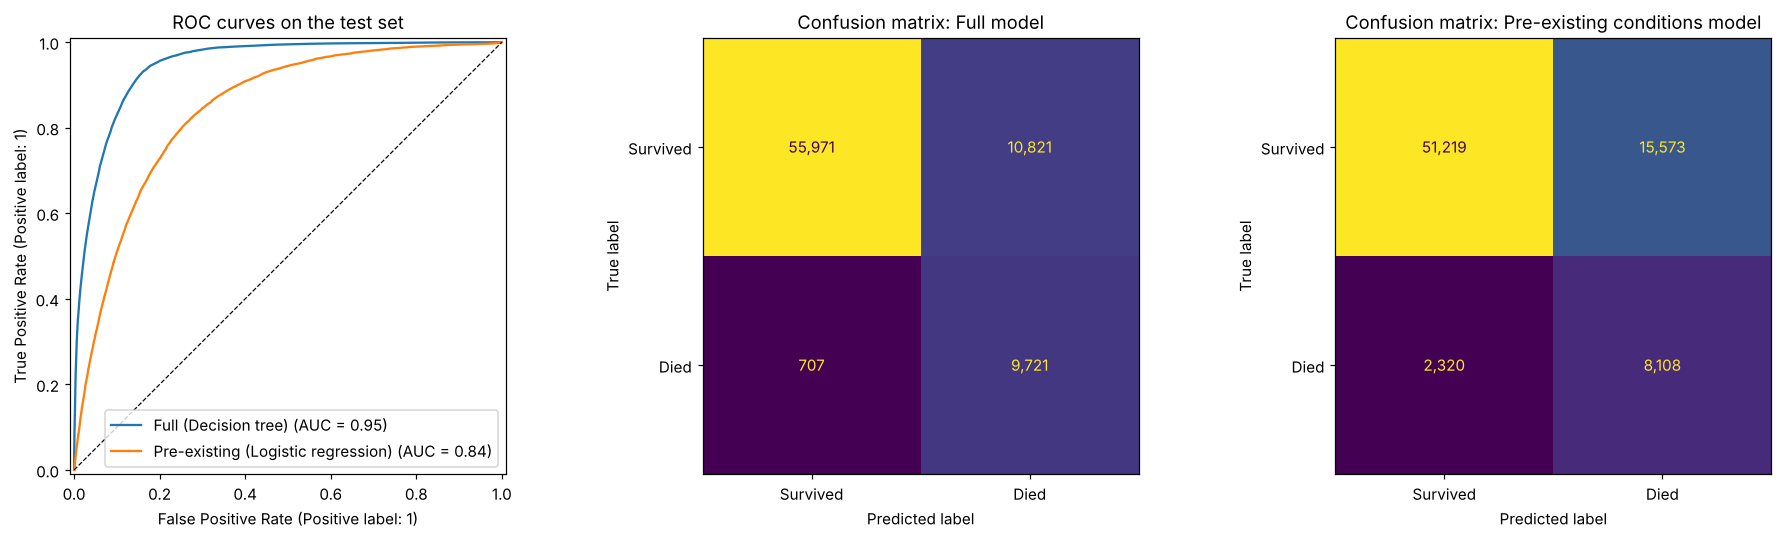

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

RocCurveDisplay.from_predictions(y_test, full_proba, ax=axes[0], name=f"Full ({full_name})")
RocCurveDisplay.from_predictions(y_test, pre_proba, ax=axes[0], name=f"Pre-existing ({pre_name})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_title("ROC curves on the test set")

for ax, pred, title in [(axes[1], full_pred, "Full model"),
                        (axes[2], pre_pred, "Pre-existing conditions model")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Survived", "Died"], ax=ax, colorbar=False,
        values_format=",")
    ax.set_title(f"Confusion matrix: {title}")

plt.tight_layout()
plt.savefig(IMAGE_DIR / "test_results.png", bbox_inches="tight")
plt.show()

## Interpreting the decision tree

A decision tree's splits can be read as plain if/then rules. Below is a shallow (depth 3) tree trained on the pre-existing conditions. It's less accurate than the tuned model, but it is small enough to read and shows which factors the model relies on first. Each leaf shows the share of patients who died (after rebalancing).

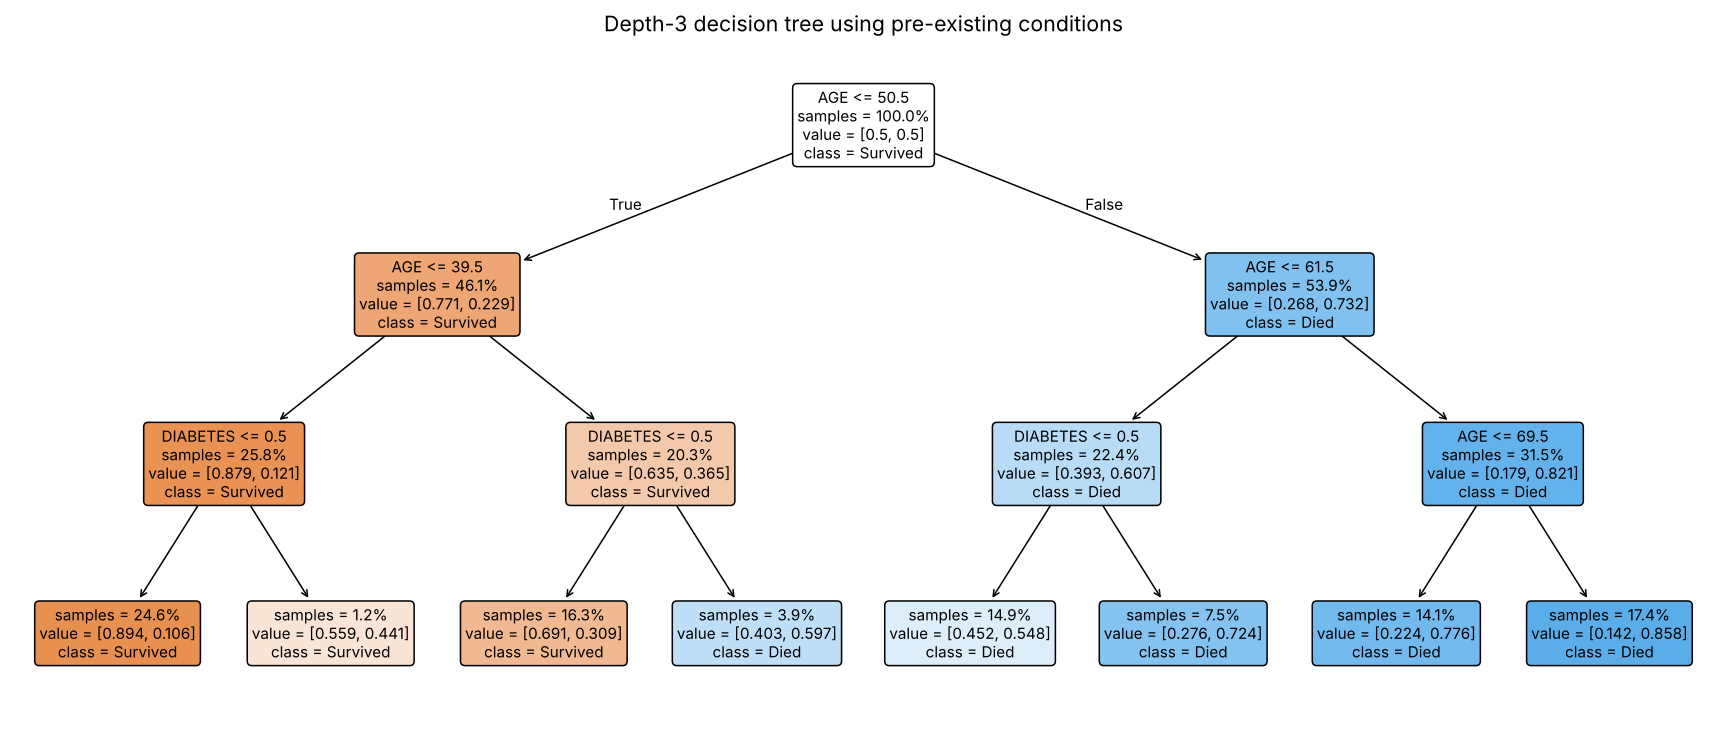

In [11]:
viz_tree = make_pipeline(DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                                random_state=RANDOM_STATE))
viz_tree.fit(X_train[pre_selected], y_train)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(viz_tree.named_steps["model"], feature_names=pre_selected,
          class_names=["Survived", "Died"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=10, ax=ax)
ax.set_title("Depth-3 decision tree using pre-existing conditions", fontsize=14)
plt.savefig(IMAGE_DIR / "decision_tree.png", bbox_inches="tight")
plt.show()

## Example: estimating risk for individual patients

The pre-existing conditions model outputs a probability, so we can estimate risk for hypothetical patients.

**Note:** the model was trained on oversampled (50/50) data, so these probabilities are inflated compared with real-world mortality rates. Use them to compare patients against each other, not as true death rates. To get calibrated probabilities you would recalibrate on the original class balance (for example with `CalibratedClassifierCV`).

In [12]:
examples = pd.DataFrame([
    {"AGE": 30, "MALE": 0},
    {"AGE": 65, "MALE": 1},
    {"AGE": 65, "MALE": 1, "DIABETES": 1, "HYPERTENSION": 1, "OBESITY": 1},
    {"AGE": 80, "MALE": 1, "CHRONIC_KIDNEY_DISEASE": 1, "DIABETES": 1},
], index=["30F, healthy", "65M, healthy", "65M, diabetes + hypertension + obesity",
          "80M, kidney disease + diabetes"]).reindex(columns=PRE_EXISTING_FEATURES).fillna(0)

examples["Relative risk score"] = pre_model.predict_proba(examples[pre_selected])[:, 1]
examples[["Relative risk score"]].style.format("{:.1%}")

,Relative risk score
"30F, healthy",7.2%
"65M, healthy",70.0%
"65M, diabetes + hypertension + obesity",90.6%
"80M, kidney disease + diabetes",98.0%


## Takeaways

- **Hospital-course features dominate.** Once a patient is hospitalized, intubated or has pneumonia, they are much more likely to die. These features push the full model's AUC up, but they describe how sick someone already is rather than their underlying risk.
- **Pre-existing conditions alone still predict well** (test AUC about 0.84 vs. 0.95 for the full model). Age is by far the strongest single factor: mortality rises from about 3% or less for patients under 40 to about 50% for patients over 80. Being male, diabetes, obesity and chronic kidney disease add the most risk on top of age.
- **High raw mortality isn't the same as an independent effect.** Cardiovascular disease has one of the highest raw mortality rates, but the L1 model drops it. That's likely because heart-disease patients tend to be older and have other conditions, so once those are known, cardiovascular disease adds little new information.
- **Fixing the methodology matters.** An earlier version of this project oversampled *before* splitting the data, which leaked duplicate patients into the test set and inflated the results. It also left the 98/99 "unknown" codes in the data as large numbers. The numbers in this notebook come from a clean held-out test set.

**Possible next steps:** calibrate the predicted probabilities, try gradient-boosted trees, and account for the hospital (`MEDICAL_UNIT`) as a source of variation.